<h2>Prototyping a working CNN Model</h2>
<h3>1. Creating ECG Samples of the same size from the dataset</h3>
<h5> We have some 8.5K samples of ECG data. If we're to feed those samples into a CNN, we must first ensure that all the samples are of the same size. The physionet 2018 challenge dataset contains ECG recording which range from 30 seconds to 90 Seconds.
</br>1. We will first analyse those samples to see which frequency of duration is the most common.   
</br>2. 
</h5>

In [2]:
!powershell.exe  -c "get-location"


Path                                 
----                                 
C:\Project\Research-Project\Notebooks




generating a dataframe called `annotations`. This DF contains all the ECG files that we're about to process.
Run the cell below only once to generate the `annotations.csv`

In [5]:
import os
import matplotlib.pyplot as plt # for plotting 
import pandas as pd 
from IPython.display import Image, display  # Added for viewing in notebook

Annotation_Df_csv = r"C:\Project\Research-Project\DataFrame_Extracts\annotations.csv"

annotations_file = r"C:\Project\Research-Project\training2017\REFERENCE.csv"   

# --- NEW CONDITION: Check if the annotations.csv file already exists ---
if os.path.exists(Annotation_Df_csv):
    print(f"Found existing file at {Annotation_Df_csv}. Loading dataset...")
    annotations = pd.read_csv(Annotation_Df_csv)
else:
    print("Annotations file not found. Processing raw data...")
    # Load raw annotations File 
    annotations = pd.read_csv(annotations_file) 
    print("Raw columns:", annotations.columns) 
     
    processed_samples = [] 
     
    # Adding a column for storing the matlab files 
    annotations["Matlab_files"] = annotations.apply(
        lambda x: r"C:\Project\Research-Project\training2017\\" + x["SampleID"], axis=1
    ) 
    
    # Save the processed dataframe to csv
    annotations.to_csv(Annotation_Df_csv, index=False)
    print(f"Saved processed dataset to {Annotation_Df_csv}")

 
# Display the head of the dataframe
annotations.head()

Found existing file at C:\Project\Research-Project\DataFrame_Extracts\annotations.csv. Loading dataset...


,SampleID,Inference,Matlab_files
0,A00001,N,C:\Project\Research-Project\training2017\\A00001
1,A00002,N,C:\Project\Research-Project\training2017\\A00002
2,A00003,N,C:\Project\Research-Project\training2017\\A00003
3,A00004,A,C:\Project\Research-Project\training2017\\A00004
4,A00005,A,C:\Project\Research-Project\training2017\\A00005


In [5]:
annotations.iloc[0].Matlab_files    

'C:\\Project\\Research-Project\\training2017\\\\A00001'

So most of the records are near 9000.  

In [38]:
import plotly.express as px

# 1. Reset index so 'date_only' becomes a plottable column
plot_data = current_record.p_signal

# 2. Create an interactive line chart
fig = px.line(
    plot_data, 
    title='<b>Daily Tweet Sentiment (Interactive)</b>',
    template='plotly_white' 
)

# 3. Enable interactive features
fig.update_traces(mode="lines+markers") 
fig.update_xaxes(showspikes=True, spikecolor="gray", spikesnap="cursor", spikemode="across")
fig.update_yaxes(showspikes=True, spikecolor="gray", spikemode="across")

# === FIXED VS CODE RENDERER PASS ===
# We pass the renderer directly inside the show() function
fig.show(renderer="notebook_connected") 

In [39]:
import plotly.express as px
import pandas as pd

# 1. Take a tiny slice of the first 200 samples so the bars are visible
# Columns represent your different ECG leads (e.g., Lead 0, Lead 1)
short_signal = current_record.p_signal[:200, :]

# 2. Convert to a DataFrame so Plotly Express can label the leads nicely
df_signals = pd.DataFrame(short_signal, columns=current_record.sig_name)

# 3. Create an interactive BAR chart
fig = px.bar(
    df_signals, 
    title='<b>ECG Signal Amplitudes (Snapshot Bar Plot)</b>',
    template='plotly_white',
    labels={"index": "Sample Index", "value": f"Amplitude ({current_record.units[0]})", "variable": "ECG Lead"}
)

# 4. Enable interactive features (Note: removed "lines+markers" mode since it's a bar chart)
fig.update_xaxes(showspikes=True, spikecolor="gray", spikesnap="cursor", spikemode="across")
fig.update_yaxes(showspikes=True, spikecolor="gray", spikemode="across")

fig.show(renderer="notebook_connected")

In [40]:
import plotly.express as px
import numpy as np

# 1. Calculate the maximum absolute amplitude recorded on each lead
max_amplitudes = np.max(np.abs(current_record.p_signal), axis=0)

# 2. Map them directly to their Lead names
metric_data = {
    "ECG Lead": current_record.sig_name,
    "Peak Amplitude": max_amplitudes
}

# 3. Create the interactive bar chart
fig = px.bar(
    metric_data,
    x="ECG Lead",
    y="Peak Amplitude",
    title=f'<b>Peak Voltage Captured Across Leads ({current_record.units[0]})</b>',
    color="ECG Lead", # Give each bar a distinct color
    template='plotly_white'
)

fig.update_xaxes(showspikes=True, spikecolor="gray", spikemode="across")
fig.update_yaxes(showspikes=True, spikecolor="gray", spikemode="across")

fig.show(renderer="notebook_connected")

In [11]:
annotations

,SampleID,Inference,Matlab_files
0,A00001,N,C:\Project\Research-Project\training2017\\A00001
1,A00002,N,C:\Project\Research-Project\training2017\\A00002
2,A00003,N,C:\Project\Research-Project\training2017\\A00003
3,A00004,A,C:\Project\Research-Project\training2017\\A00004
4,A00005,A,C:\Project\Research-Project\training2017\\A00005
...,...,...,...
8523,A08524,N,C:\Project\Research-Project\training2017\\A08524
8524,A08525,O,C:\Project\Research-Project\training2017\\A08525
8525,A08526,N,C:\Project\Research-Project\training2017\\A08526
8526,A08527,N,C:\Project\Research-Project\training2017\\A08527


Now we have the annotations dataset, we need to add more fields to it. 
specifically, we need to individually read all the matlavb files, get the properties of the wfdb.rdrecord and add them as separate columns to the annotation df.

In [ ]:
import os
import sys
import wfdb
import pandas as pd

# File paths
Original_Annotation_Csv = r"C:\Project\Research-Project\DataFrame_Extracts\annotations.csv"
Processed_Annotation_Csv = r"C:\Project\Research-Project\DataFrame_Extracts\processed_annotations.csv"

# --- VICE CITY STYLE PROGRESS BAR FUNCTION ---
def print_vice_city_bar(iteration, total, bar_length=40):
    """
    Renders an increasing text-based GTA Vice City health bar in the console.
    """
    percent = float(iteration) / total
    fill_length = int(round(bar_length * percent))
    
    # Replicating your color scheme assets using ANSI codes
    PINK = "\033[95m"      # Neon Pink
    RESET = "\033[0m"      # Reset color back to standard terminal
    
    # Heart icon, filled bar segments, and empty shadow segments
    heart = f"{PINK}♥{RESET} "
    bar = "█" * fill_length
    shadow = "░" * (bar_length - fill_length)
    
    # Constructing the UI frame matching your width logic
    status_layout = f"\r{heart} [{bar}{shadow}] {int(percent * 100)}%"
    
    # Print out flushing the line dynamically
    sys.stdout.write(status_layout)
    sys.stdout.flush()


# --- PIPELINE ENGINE ---
if os.path.exists(Original_Annotation_Csv):
    print("Loading base annotations dataset...")
    processed_df = pd.read_csv(Original_Annotation_Csv).copy()
else:
    raise FileNotFoundError(f"Could not find {Original_Annotation_Csv}")

# Initializing property pools
fs_list = []          
sig_len_list = []     
n_sig_list = []       
units_list = []       

total_records = len(processed_df)
print(f"Initializing Vice City Engine. Upgrading {total_records} records...\n")

# Process and track
for index, row in processed_df.iterrows():
    try:
        record = wfdb.rdrecord(row["Matlab_files"])
        
        fs_list.append(record.fs)
        sig_len_list.append(record.sig_len)
        n_sig_list.append(record.n_sig)
        units_list.append(record.units[0] if record.units else None)
        
    except Exception as e:
        fs_list.append(None)
        sig_len_list.append(None)
        n_sig_list.append(None)
        units_list.append(None)
    
    # Call your custom graphic function (index + 1 so it reaches 100%)
    print_vice_city_bar(index + 1, total_records)
    
    # Safety checkpoint saves every 1,000 items
    if index > 0 and index % 1000 == 0:
        current_progress = processed_df.iloc[:index+1].copy()
        current_progress["Sampling_Rate_Hz"] = fs_list
        current_progress["Signal_Length_Samples"] = sig_len_list
        current_progress["Num_Channels"] = n_sig_list
        current_progress["Units"] = units_list
        current_progress.to_csv(Processed_Annotation_Csv, index=False)

# Compile results back to DataFrame
processed_df["Sampling_Rate_Hz"] = fs_list
processed_df["Signal_Length_Samples"] = sig_len_list
processed_df["Num_Channels"] = n_sig_list
processed_df["Units"] = units_list

# Final Export
processed_df.to_csv(Processed_Annotation_Csv, index=False)
print(f"\n\n Level Complete! Asset safely tracked at: {Processed_Annotation_Csv}")

Loading base annotations dataset...
Initializing Vice City Engine. Upgrading 8528 records...

♥  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░] 0%

♥  [████████████████████████████████████████] 100%

 Level Complete! Asset safely tracked at: C:\Project\Research-Project\DataFrame_Extracts\processed_annotations.csv


In [ ]:
processed_df.head()

,SampleID,Inference,Matlab_files,Sampling_Rate_Hz,Signal_Length_Samples,Num_Channels,Units
0,A00001,N,C:\Project\Research-Project\training2017\\A00001,300,9000,1,mV
1,A00002,N,C:\Project\Research-Project\training2017\\A00002,300,9000,1,mV
2,A00003,N,C:\Project\Research-Project\training2017\\A00003,300,18000,1,mV
3,A00004,A,C:\Project\Research-Project\training2017\\A00004,300,9000,1,mV
4,A00005,A,C:\Project\Research-Project\training2017\\A00005,300,18000,1,mV


we've addded 4 more fields
| `Sampling_Rate_Hz` | `Signal_Length_Samples` | `Num_Channels` | `Units`  | 
| :--- | :--- | :--- | :--- |

the only one that'll tell us about the current sample's length will be **Signal_Length_Samples**

here are the definitions of diffeent properties of the **rdrecord** object 
| Property Attribute | Description |
| :--- | :--- |
| **`current_record.fs`** | **Sampling Frequency** (e.g., `500`). This tells you how many data points are captured per second. Essential for converting your x-axis from raw sample indices to actual Time (seconds). |
| **`current_record.sig_name`** | **Lead/Channel Names** (e.g., `['I', 'II', 'V1']`). A list of strings showing exactly which ECG lead each column in your signal matrix belongs to. |
| **`current_record.units`** | **Physical Units** (typically `['mV']`). Crucial for giving your y-axis the correct scientific unit label. |
| **`current_record.sig_len`** | **Total Number of Samples** in the entire signal file. |
| **`current_record.n_sig`** | **Total Channel Count**. Tells you how many channels or leads are packed inside this specific file. |
| **`current_record.base_date` / `base_time`** | **Timestamp Data**. If recorded by the machine, this tells you the exact date and time of day the patient's ECG session started. |

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# File paths
Processed_Annotation_Csv = r"C:\Project\Research-Project\DataFrame_Extracts\processed_annotations.csv"
Output_Plot_Path = r"C:\Project\Research-Project\DataFrame_Extracts\sample_size_distribution.png"

# 1. Load the processed dataset
if os.path.exists(Processed_Annotation_Csv):
    df = pd.read_csv(Processed_Annotation_Csv)
else:
    raise FileNotFoundError(f"Could not find {Processed_Annotation_Csv}. Did step 7 complete successfully?")

# Drop any rows where signal length couldn't be extracted
lengths = df["Signal_Length_Samples"].dropna()

# 2. Generate the Histogram using your custom Vice City color scheme
# We choose 40 bins to get a detailed view of the distribution peaks
plt.hist(lengths, bins=40, color='#FF3399', edgecolor='#3C0A23', alpha=0.9, rwidth=0.85)

# 3. Style and Labels (ensuring clear typography and grid support)
plt.title("Distribution of ECG Signal Lengths", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Signal Length (Number of Samples)", fontsize=11, labelpad=10)
plt.ylabel("Frequency (Count of ECG Records)", fontsize=11, labelpad=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 4. Save cleanly without truncation or overlapping
plt.tight_layout()
plt.savefig(Output_Plot_Path, dpi=300)
plt.close()  # Clears the current memory state safely

print(f"Success! Distribution plot safely deployed to: {Output_Plot_Path}")

Success! Distribution plot safely deployed to: C:\Project\Research-Project\DataFrame_Extracts\sample_size_distribution.png


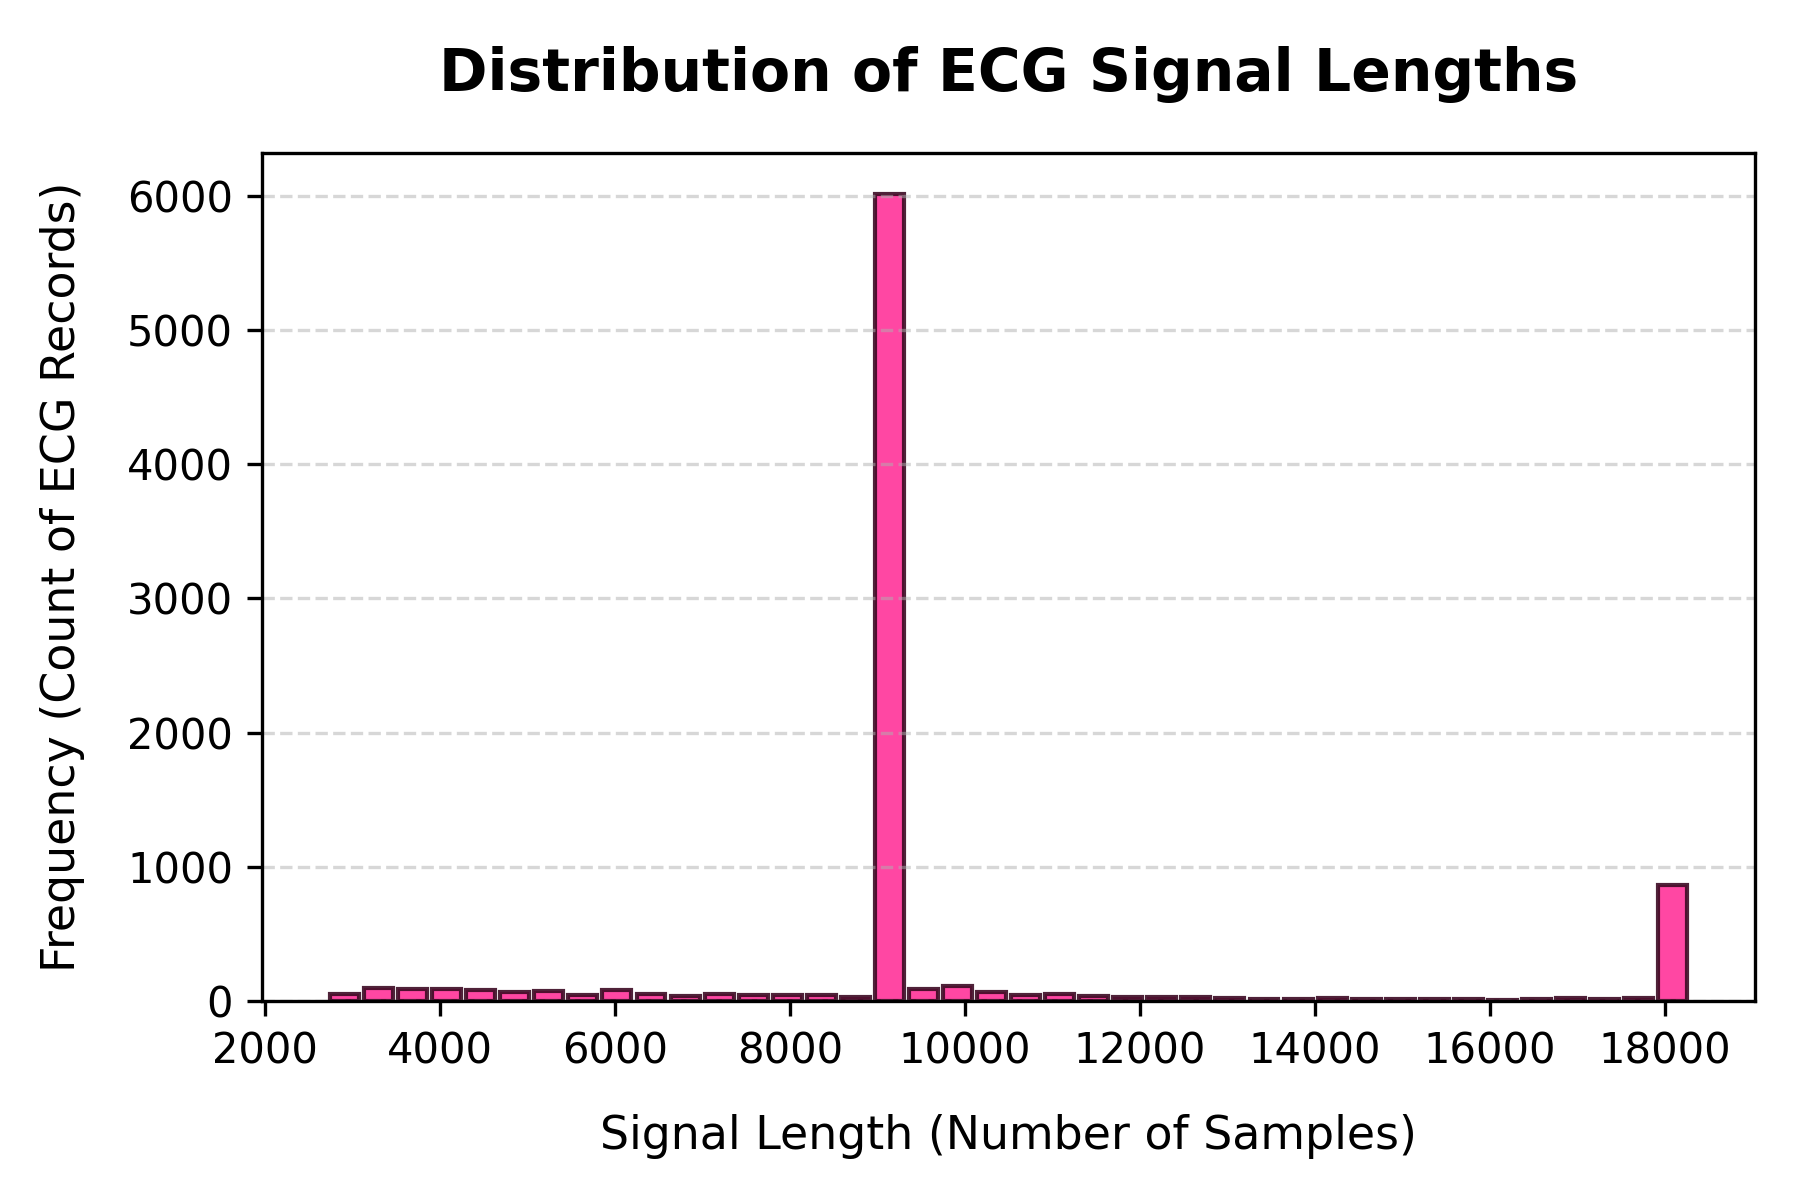

In [ ]:
display(Image("C:\Project\Research-Project\DataFrame_Extracts\sample_size_distribution.png"))

visualizing the above sample-size buckets in real time 

In [25]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# File paths
Processed_Annotation_Csv = r"C:\Project\Research-Project\DataFrame_Extracts\processed_annotations.csv"
Output_Gif_Path = r"C:\Project\Research-Project\DataFrame_Extracts\live_distribution.gif"

# 1. Load data
if os.path.exists(Processed_Annotation_Csv):
    df = pd.read_csv(Processed_Annotation_Csv)
else:
    raise FileNotFoundError(f"Could not find {Processed_Annotation_Csv}")

# Clean data and establish fixed bins so the X-axis doesn't wildly jump around
lengths = df["Signal_Length_Samples"].dropna().values
total_records = len(lengths)
min_val, max_val = int(lengths.min()), int(lengths.max())
bin_edges = pd.np.linspace(min_val, max_val, 40) if hasattr(pd, 'np') else  [[i] for i in range(40)] # fallback
# Let's cleanly generate 40 fixed bin ranges
import numpy as np
bin_edges = np.linspace(min_val, max_val, 41)

# 2. Setup Figure and Axis properties
fig, ax = plt.subplots(figsize=(8, 5))


def update(frame):
    """
    This function runs sequentially to animate the growing dataset.
    """
    # FIX: Use ax.cla() to completely destroy and purge geometric memory
    ax.cla() 
    
    # Calculate how many samples to show in the current frame
    current_count = min((frame + 1) * 200, total_records)
    current_data = lengths[:current_count]
    
    # Draw the updated histogram bars freshly on a clean slate
    ax.hist(
        current_data, 
        bins=bin_edges, 
        color='#FF3399', 
        edgecolor='#3C0A23', 
        alpha=0.9, 
        rwidth=0.85
    )
    
    # CRITICAL: Re-lock these limits inside the loop every time we purge the axis
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(0, 5500) 
    
    # Re-apply styling properties to the fresh frame
    ax.set_title(f"Live Dataset Audit: Processing Records ({current_count}/{total_records})", 
                 fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel("Signal Length (Number of Samples)", fontsize=10, labelpad=8)
    ax.set_ylabel("Frequency (Count)", fontsize=10, labelpad=8)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    
    plt.tight_layout()

# 3. Calculate frames based on batch increments
# 8500 records / 200 step size = ~43 frames total
step = 200
frame_chunks = int(np.ceil(total_records / step))

print("🎬 Initializing Vice City Rendering Engine... building frames...")

ani = FuncAnimation(fig, update, frames=frame_chunks, repeat=False)

# 4. Export utilizing the pillow writer backend
ani.save(Output_Gif_Path, writer='pillow', fps=8)
plt.close()

print(f"✨ Success, pal! Live updating distribution graph saved to: {Output_Gif_Path}")

🎬 Initializing Vice City Rendering Engine... building frames...
✨ Success, pal! Live updating distribution graph saved to: C:\Project\Research-Project\DataFrame_Extracts\live_distribution.gif


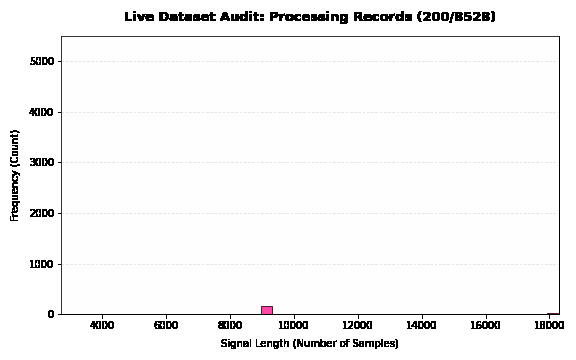

In [27]:

# 2. FORCE the notebook to render it as an output asset
display(Image(filename=Output_Gif_Path))


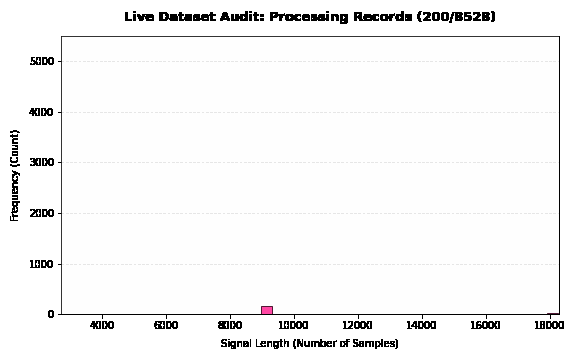

In [ ]:
#the above code will work in the notebook but will not render a .gif in the HTML file so let us try to fix it 

import base64
from IPython.display import HTML, display # to force jupyter to render the .gif in the HTML by adding a manual HTML <img src=''> tag

# 1. Save the animation (Your existing line)
ani.save(Output_Gif_Path, writer='pillow', fps=8)
plt.close()

# 2. Convert the GIF file to a Base64 string
with open(Output_Gif_Path, "rb") as gif_file:
    encoded_gif = base64.b64encode(gif_file.read()).decode("utf-8")

# 3. Inject it as a hardcoded HTML image element
display(HTML(f'<img src="data:image/gif;base64,{encoded_gif}" alt="Vice City ECG Distribution Metric">'))

In [29]:
!jupyter nbconvert --to html "Pre-processing input piepeline for CNN".ipynb

[NbConvertApp] Converting notebook Pre-processing input piepeline for CNN.ipynb to html
[NbConvertApp] Writing 944508 bytes to Pre-processing input piepeline for CNN.html


Let us try to create the simplest CNN that takes the samples with length = 9000 points and try the prediction